# 4. Which differences are real?

Notebook 3 described the sales: one city sells a bit more, Saturday looks strong, 19:00 looks busy. But any group of numbers has a top and a bottom, and a difference can appear by pure luck. This notebook tests each claim, using the code in `market_sales/stats.py`.

**This is sample data**, so the answers describe this file and aren't about real shoppers.

## How to read the results

Each question gets three numbers:

- **p-value:** if there were truly *no* difference, how often would luck alone produce a gap at least this large? A small p-value (below 0.05) means luck is an unlikely explanation.
- **Adjusted p-value:** with 22 questions, about one will look significant by luck alone, so the p-values are raised to account for that (Holm's method). **The adjusted value is the one that decides the verdict.**
- **Effect size:** how big the difference is, on a 0 to 1 scale. It separates a difference that is *real* from one that is *large*.

For claims like "Saturday beats Monday", picking the best and worst of seven days always makes a gap look big, so those are tested by shuffling: the weekday labels are shuffled thousands of times to see how big a best-versus-worst gap pure chance produces.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from market_sales import charts
from market_sales.cleaning import load_clean
from market_sales.config import RAW_DATA
from market_sales.stats import detectable_differences, power_city_order_size, power_weekday, run_all

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

df = load_clean(RAW_DATA)
results = run_all(df)

## All the results

In [2]:
table = results[["family", "question", "p_value", "p_adjusted", "effect_size", "effect_name", "verdict"]].copy()
table.columns = ["Area", "Question", "p-value", "Adjusted p", "Effect size", "Measured as", "Verdict"]
table.style.hide(axis="index").format({"p-value": "{:.3f}", "Adjusted p": "{:.3f}", "Effect size": "{:.3f}"})

Area,Question,p-value,Adjusted p,Effect size,Measured as,Verdict
City,Do the cities make the same number of sales?,0.894,1.000,0.015,Cohen's w,No evidence of a difference
City,Does the average sale differ between cities?,0.812,1.000,0.000,epsilon-squared,No evidence of a difference
City,Is the gap between the best and worst city's total sales more than chance?,0.801,1.000,0.041,relative gap,No evidence of a difference
City,Do customers rate the cities differently?,0.130,1.000,0.004,epsilon-squared,No evidence of a difference
Product line,Are some product lines bought more often?,0.743,1.000,0.052,Cohen's w,No evidence of a difference
Product line,Does the average sale differ between product lines?,0.827,1.000,0.002,epsilon-squared,No evidence of a difference
Product line,Is the gap between the best and worst line's total sales more than chance?,0.894,1.000,0.141,relative gap,No evidence of a difference
Product line,Do customers rate product lines differently?,0.742,1.000,0.003,epsilon-squared,No evidence of a difference
Product line,Does each city really favour different product lines?,0.316,1.000,0.076,Cramer's V,No evidence of a difference
Time,Do daily sales differ by day of the week?,0.354,1.000,0.076,epsilon-squared,No evidence of a difference


In [3]:
counts = results["verdict"].value_counts()
print(f"{len(results)} questions tested.")
for verdict in ["Real difference", "Possible, not convincing", "No evidence of a difference"]:
    print(f"  {verdict}: {counts.get(verdict, 0)}")
print()
print("Closest to being interesting:")
closest = results.nsmallest(4, "p_value")[["question", "p_value", "p_adjusted"]]
for row in closest.itertuples():
    print(f"  p = {row.p_value:.3f} (adjusted {row.p_adjusted:.2f}): {row.question}")

22 questions tested.
  Real difference: 0
  Possible, not convincing: 0
  No evidence of a difference: 22

Closest to being interesting:
  p = 0.050 (adjusted 1.00): Are some hours of the day busier than others?
  p = 0.052 (adjusted 1.00): Do weekend days sell more than weekdays?
  p = 0.101 (adjusted 1.00): Do women and men spend differently per sale?
  p = 0.130 (adjusted 1.00): Do customers rate the cities differently?


None of the differences survives the adjustment. The smallest p-values are just around 0.05, which is what you'd expect from 22 tests of data with no real patterns in it.

## Looking closer

### Days of the week

Saturday's average looked 37% above Monday's. Here is every day's sales, grouped by weekday:

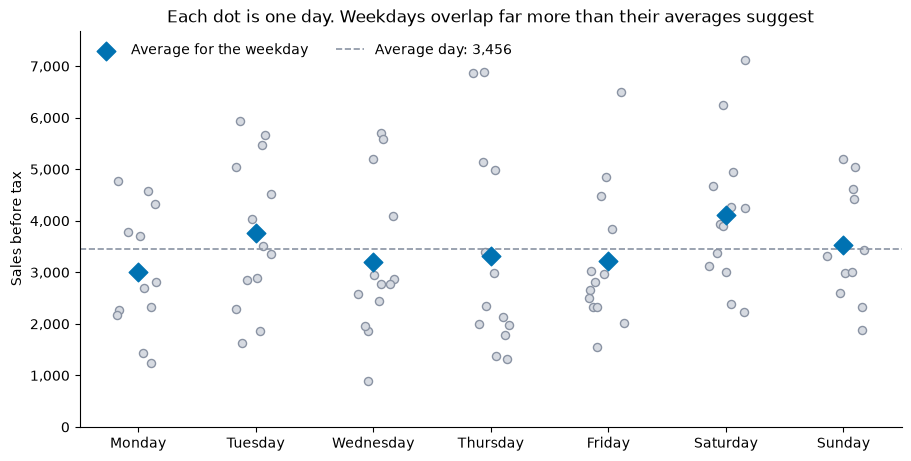

In [4]:
charts.weekday_spread(df)

The dots overlap heavily: some Mondays beat some Saturdays. The averages differ, but the days vary so much that it's hard to tell a real weekday effect from luck. The shuffling test makes that precise:

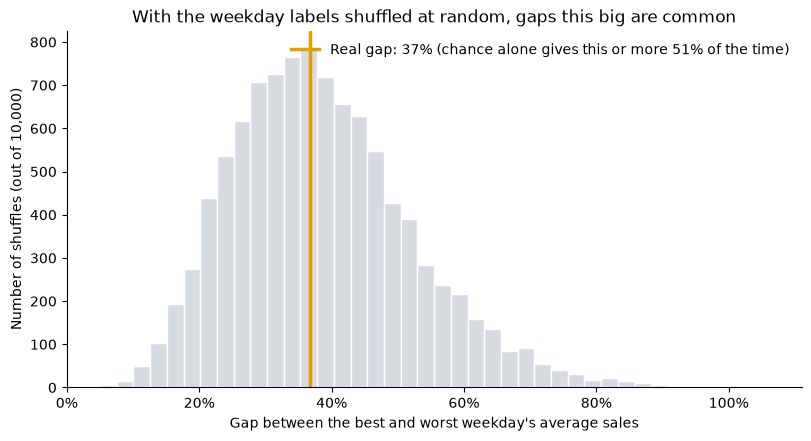

In [5]:
charts.weekday_gap_by_chance(df)

In [6]:
weekday = results.set_index("id").loc["weekday_gap"]
print(f"A best-versus-worst gap of {weekday['effect_size']:.0%} or more shows up {weekday['p_value']:.0%} of the time when weekday labels are shuffled at random.")
print("So a gap this size is what chance routinely produces. It isn't evidence of a weekday pattern.")

A best-versus-worst gap of 37% or more shows up 51% of the time when weekday labels are shuffled at random.
So a gap this size is what chance routinely produces. It isn't evidence of a weekday pattern.


### Cities

The three cities' average sales, each with the range it could plausibly be in:

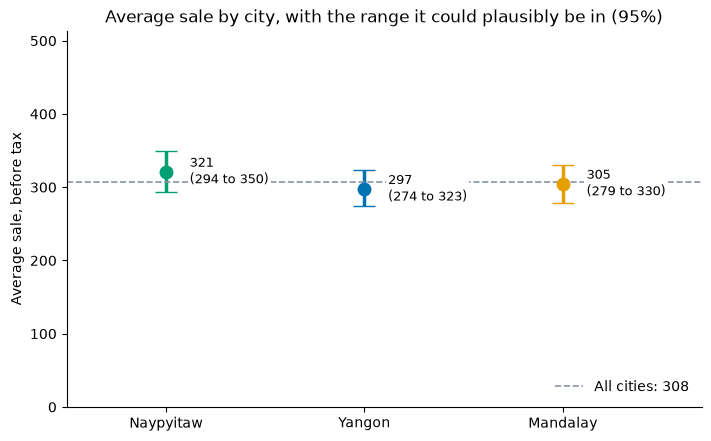

In [7]:
charts.city_order_intervals(df)

The ranges overlap almost completely, so the data can't tell the cities apart.

### The borderline cases

Two tests landed right on the edge of 0.05 *before* adjusting: whether weekends out-sell weekdays, and whether some hours are busier.

In [8]:
edge = results[results["id"].isin(["weekend", "hour_orders"])][["question", "p_value", "p_adjusted"]]
edge.style.hide(axis="index").format({"p_value": "{:.3f}", "p_adjusted": "{:.3f}"})

question,p_value,p_adjusted
Do weekend days sell more than weekdays?,0.052,1.000
Are some hours of the day busier than others?,0.050,1.000


These are hints worth a closer look with more data, not findings. Note that the hour test asks whether hours differ at all. It does not show that 19:00 specifically is the best, which is a separate question and a much weaker result (p = 0.31). Once the number of tests is taken into account they're nowhere near significant.

## Can these tests find anything at all?

Finding nothing only means something if the tests would have noticed a real difference. To check, a known boost is planted in the data and the tests are run again, over and over:

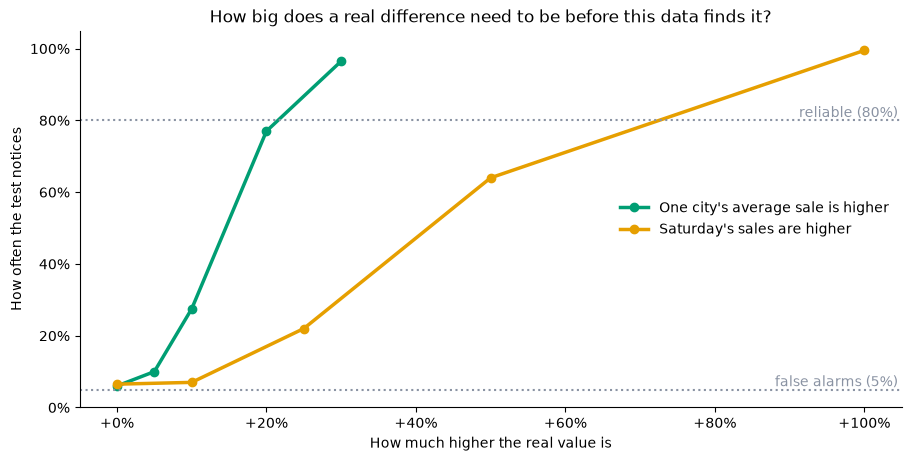

In [9]:
city_power = power_city_order_size(df)
weekday_power = power_weekday(df)
charts.detection_power(city_power, weekday_power)

In [10]:
no_boost = city_power.loc[0, "detected"]
print(f"With no boost planted, the city test raised a false alarm {no_boost:.0%} of the time, close to the 5% it should.")
for lift in [0.1, 0.2, 0.3]:
    found = city_power.loc[city_power["lift"] == lift, "detected"].iloc[0]
    print(f"A real {lift:.0%} boost to one city's average sale was noticed {found:.0%} of the time.")
for lift in [0.25, 0.5, 1.0]:
    found = weekday_power.loc[weekday_power["lift"] == lift, "gap_detected"].iloc[0]
    print(f"A real +{lift:.0%} Saturday boost was noticed {found:.0%} of the time.")

With no boost planted, the city test raised a false alarm 6% of the time, close to the 5% it should.
A real 10% boost to one city's average sale was noticed 28% of the time.
A real 20% boost to one city's average sale was noticed 77% of the time.
A real 30% boost to one city's average sale was noticed 96% of the time.
A real +25% Saturday boost was noticed 22% of the time.
A real +50% Saturday boost was noticed 64% of the time.
A real +100% Saturday boost was noticed 100% of the time.


The tests behave properly: few false alarms, and big differences are found. The city comparison is fairly sensitive. The weekday comparison is not, because there are only 12 or 13 of each weekday in 89 days.

In [11]:
needed = detectable_differences(df)
needed["as_share_of_average"] = needed["as_share_of_average"].map("{:.0%}".format)
needed["smallest_detectable"] = needed["smallest_detectable"].map("{:,.0f}".format)
needed.rename(columns={"comparison": "Comparison", "smallest_detectable": "Smallest gap reliably found", "as_share_of_average": "As a share of the average"}).style.hide(axis="index")

Comparison,Smallest gap reliably found,As a share of the average
Average sale: one city vs another,51,16%
Average sale: members vs others,41,13%
Average sale: women vs men,41,13%
Daily sales: one weekday vs another,"1,617",47%
Daily sales: weekend vs weekdays,961,28%


## What we can and can't say

**We can say:**

- The three cities are indistinguishable on sales, average sale and rating. A difference of 20% to 30% or more would usually have been found, and none was.
- Members, non-members, women, men and the three payment methods all look alike.
- The product mix doesn't clearly differ between cities, even though each city's top line is different.

**We can't say:**

- That Saturday isn't better than other days. A real boost of +50% was noticed only about 64% of the time, and it takes roughly +70% before the data finds it reliably, so a smaller real effect could be hiding.
- That every hour is equally busy. The test for uneven hours landed right on the edge (p = 0.050 before adjusting), so it's worth rechecking with more data. Singling out 19:00 as the best hour isn't supported, though: a best-versus-worst hour gap this big appears about 31% of the time by chance.

**"Not significant" is not the same as "no difference".** It means the data doesn't show one. The last table says how large a difference needed to be to show up.

That is a normal result for data that looks like this. Prices, quantities and ratings are spread almost evenly with no relationships between them, which is typical of sample data and rare in real shops. With real data there would probably be genuine patterns to find, and the same code would find them.